In [1]:
import pandas as pd

listings = pd.read_csv("../data/raw/listings.csv.gz")
neighbourhoods = pd.read_csv("../data/raw/neighbourhoods.csv")
print(listings.shape)

(31069, 90)


In [2]:
empty_cols = listings.columns[listings.isnull().all()]
print("Dropping:", list(empty_cols))
df = listings.drop(columns=empty_cols)
print(df.shape)

cols = ["price", "room_type", "neighbourhood_cleansed",
        "calculated_host_listings_count", "number_of_reviews",
        "review_scores_rating", "availability_365"]
print(df[cols].isnull().sum())
print(df[cols].dtypes)
df[cols].head()

Dropping: ['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'neighbourhood_group_cleansed', 'calendar_updated', 'license', 'instant_bookable']
(31069, 76)
price                              2082
room_type                             0
neighbourhood_cleansed                0
calculated_host_listings_count        0
number_of_reviews                     0
review_scores_rating              10253
availability_365                      0
dtype: int64
price                              object
room_type                          object
neighbourhood_cleansed             object
calculated_host_listings_count      int64
number_of_reviews                   int64
review_scores_rating              float64
availability_365                    int64
dtype: object


,price,room_type,neighbourhood_cleansed,calculated_host_listings_count,number_of_reviews,review_scores_rating,availability_365
0,"$1,148.24",Entire home/apt,Khlong Toei,44,22,4.59,357
1,NaN,Private room,Ratchathewi,8,0,NaN,346
2,$776.85,Entire home/apt,Khlong San,48,1,3.00,269
3,$723.25,Private room,Don Mueang,1,0,NaN,365
4,"$25,106.00",Entire home/apt,Khlong Toei,10,0,NaN,364


In [3]:
# 1. Convert price text -> number
df["price"] = df["price"].str.replace("$", "", regex=False).str.replace(",", "", regex=False).astype(float)

# 2. Drop missing prices and duplicates
before = len(df)
df = df.dropna(subset=["price"])
df = df.drop_duplicates(subset="id")
print("Rows removed:", before - len(df), "| Remaining:", len(df))

# 3. Check price spread
print(df["price"].describe())
print(df["price"].quantile([0.01, 0.05, 0.95, 0.99]))

Rows removed: 2082 | Remaining: 28987
count    2.898700e+04
mean     2.955960e+03
std      1.905472e+04
min      1.000000e+00
25%      1.041465e+03
50%      1.592000e+03
75%      2.539565e+03
max      1.320255e+06
Name: price, dtype: float64
0.01      288.80
0.05      560.32
0.95     6981.00
0.99    19258.24
Name: price, dtype: float64


In [4]:
# Remove price outliers (below 1st / above 99th percentile)
low, high = df["price"].quantile([0.01, 0.99])
before = len(df)
df = df[(df["price"] >= low) & (df["price"] <= high)].copy()
print(f"Kept prices between {low:.0f} and {high:.0f} THB")
print("Rows removed:", before - len(df), "| Remaining:", len(df))

# Standardize text columns
df["room_type"] = df["room_type"].str.strip()
df["neighbourhood_cleansed"] = df["neighbourhood_cleansed"].str.strip()

# Quick look at the cleaned data
print(df["price"].describe())
print(df["room_type"].value_counts())
print(df["neighbourhood_cleansed"].nunique(), "neighbourhoods")

# Save cleaned file
df.to_csv("../data/clean/listings_clean.csv", index=False)

Kept prices between 289 and 19258 THB
Rows removed: 577 | Remaining: 28410
count    28410.000000
mean      2242.749749
std       2162.677745
min        288.800000
25%       1050.562500
50%       1592.000000
75%       2505.275000
max      19256.000000
Name: price, dtype: float64
room_type
Entire home/apt    18880
Private room        8786
Shared room          470
Hotel room           274
Name: count, dtype: int64
50 neighbourhoods


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

# Q1: room type vs price and availability
room_summary = df.groupby("room_type").agg(
    listings=("id", "count"),
    median_price=("price", "median"),
    avg_availability=("availability_365", "mean")
).round(0)
print(room_summary)

# Q2: top 10 neighbourhoods by median price (min 50 listings)
nb = df.groupby("neighbourhood_cleansed").agg(
    listings=("id", "count"),
    median_price=("price", "median")
)
nb = nb[nb["listings"] >= 50].sort_values("median_price", ascending=False)
print(nb.head(10))

                 listings  median_price  avg_availability
room_type                                                
Entire home/apt     18880        1712.0             277.0
Hotel room            274        1994.0             301.0
Private room         8786        1392.0             307.0
Shared room           470         438.0             341.0
                        listings  median_price
neighbourhood_cleansed                        
Parthum Wan                  674      2640.000
Vadhana                     4046      2197.875
Lat Phrao                     79      2182.000
Samphanthawong               303      2163.990
Bang Rak                    1023      2048.000
Bueng Kum                    248      2031.300
Khlong Toei                 3640      1814.735
Ratchathewi                 1665      1750.000
Pom Prap Sattru Phai         265      1720.000
Huai Khwang                 3712      1695.230


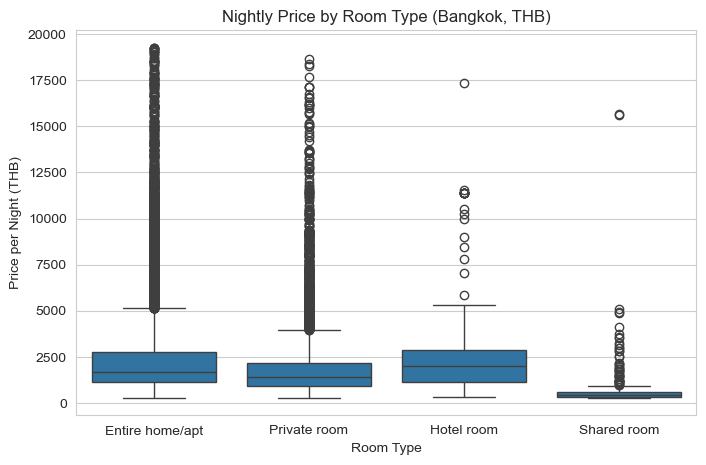

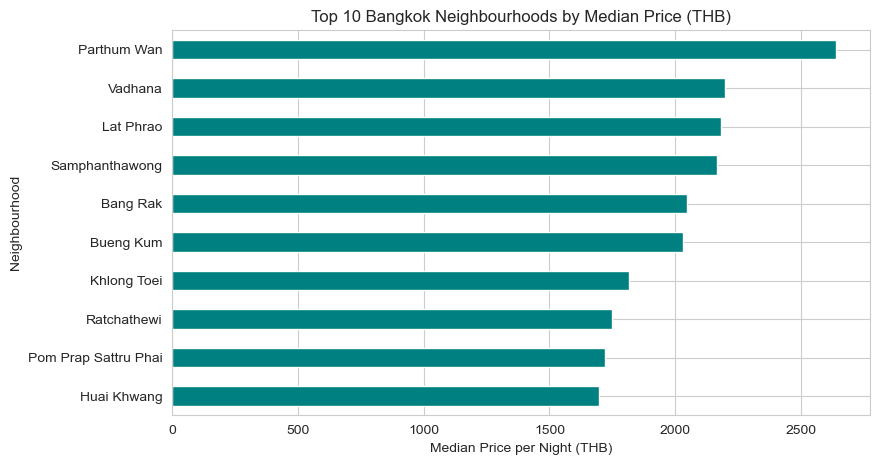

In [6]:
# Chart 1: price by room type
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="room_type", y="price")
plt.title("Nightly Price by Room Type (Bangkok, THB)")
plt.xlabel("Room Type")
plt.ylabel("Price per Night (THB)")
plt.savefig("../images/price_by_room_type.png", dpi=150, bbox_inches="tight")
plt.show()

# Chart 2: top 10 neighbourhoods
plt.figure(figsize=(9, 5))
nb.head(10)["median_price"].sort_values().plot(kind="barh", color="teal")
plt.title("Top 10 Bangkok Neighbourhoods by Median Price (THB)")
plt.xlabel("Median Price per Night (THB)")
plt.ylabel("Neighbourhood")
plt.savefig("../images/top_neighbourhoods.png", dpi=150, bbox_inches="tight")
plt.show()

              listings  median_price  avg_reviews  avg_availability
host_type                                                          
1 listing         3768        1643.3         20.2             276.0
2-5 listings      6119        1577.0         28.7             279.7
6+ listings      18523        1586.8         22.0             292.1
                      price  number_of_reviews  availability_365  \
price                  1.00               0.02             -0.05   
number_of_reviews      0.02               1.00             -0.04   
availability_365      -0.05              -0.04              1.00   
review_scores_rating   0.04               0.08             -0.07   

                      review_scores_rating  
price                                 0.04  
number_of_reviews                     0.08  
availability_365                     -0.07  
review_scores_rating                  1.00  


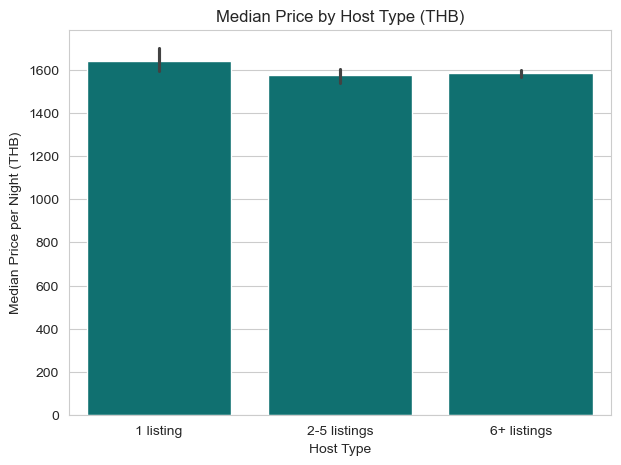

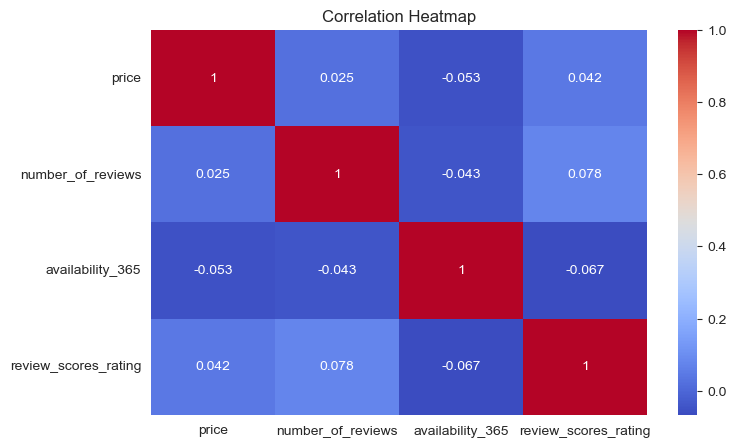

In [7]:
# Q3: single-listing hosts vs multi-listing hosts
df["host_type"] = pd.cut(df["calculated_host_listings_count"],
                         bins=[0, 1, 5, 1000],
                         labels=["1 listing", "2-5 listings", "6+ listings"])
host_summary = df.groupby("host_type", observed=True).agg(
    listings=("id", "count"),
    median_price=("price", "median"),
    avg_reviews=("number_of_reviews", "mean"),
    avg_availability=("availability_365", "mean")
).round(1)
print(host_summary)

# Q4: what relates to review score?
rated = df.dropna(subset=["review_scores_rating"])
print(rated[["price", "number_of_reviews", "availability_365",
             "review_scores_rating"]].corr().round(2))

# Charts
plt.figure(figsize=(7, 5))
sns.barplot(data=df, x="host_type", y="price", estimator="median", color="teal")
plt.title("Median Price by Host Type (THB)")
plt.xlabel("Host Type")
plt.ylabel("Median Price per Night (THB)")
plt.savefig("../images/price_by_host_type.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
sns.heatmap(rated[["price", "number_of_reviews", "availability_365",
                   "review_scores_rating"]].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.savefig("../images/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
cal_check = pd.read_csv("../data/raw/calendar.csv.gz", nrows=5)
print(cal_check.columns.tolist())
cal_check

['listing_id', 'date', 'available', 'minimum_nights', 'maximum_nights']


,listing_id,date,available,minimum_nights,maximum_nights
0,27934,2026-06-29,f,30,240
1,27934,2026-06-30,f,30,240
2,27934,2026-07-01,f,30,240
3,27934,2026-07-02,t,30,240
4,27934,2026-07-03,t,30,240


In [9]:
cal = pd.read_csv("../data/raw/calendar.csv.gz",
                  usecols=["listing_id", "date", "available"],
                  parse_dates=["date"])
print(cal.shape)
print(cal.isnull().sum())
print(cal["date"].min(), "to", cal["date"].max())
print(cal["available"].value_counts())

(11340155, 3)
listing_id    0
date          0
available     0
dtype: int64
2026-06-29 00:00:00 to 2027-07-01 00:00:00
available
t    8602917
f    2737238
Name: count, dtype: int64


month
2026-06    54.4
2026-07    27.4
2026-08    14.3
2026-09     8.9
2026-10    13.9
2026-11    15.1
2026-12    17.4
2027-01    20.6
2027-02    19.4
2027-03    20.2
2027-04    32.6
2027-05    32.3
2027-06    32.6
2027-07    35.7
Name: unavailable, dtype: float64


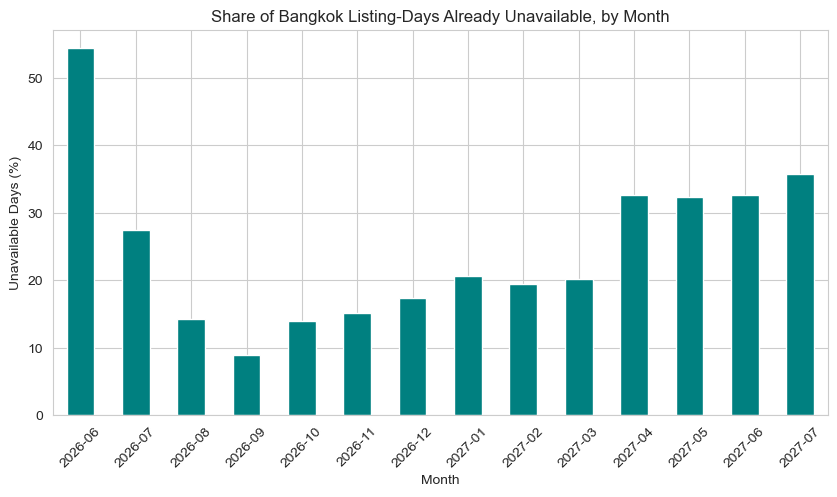

In [10]:
# Keep only listings that survived cleaning
cal = cal[cal["listing_id"].isin(df["id"])].copy()

# Unavailable flag and month
cal["unavailable"] = (cal["available"] == "f").astype(int)
cal["month"] = cal["date"].dt.to_period("M").astype(str)

monthly = cal.groupby("month")["unavailable"].mean().mul(100).round(1)
print(monthly)

plt.figure(figsize=(10, 5))
monthly.plot(kind="bar", color="teal")
plt.title("Share of Bangkok Listing-Days Already Unavailable, by Month")
plt.xlabel("Month")
plt.ylabel("Unavailable Days (%)")
plt.xticks(rotation=45)
plt.savefig("../images/monthly_unavailable.png", dpi=150, bbox_inches="tight")
plt.show()

## Key Findings & Recommendations

1. **Room type:** Entire homes have a median price of ฿1,712 vs ฿1,392 for private rooms (+23%). Shared rooms are the cheapest at ฿438.
2. **Location:** Parthum Wan is the priciest district (median ฿2,640, about 66% above the city median of ฿1,592), followed by Vadhana and Lat Phrao.
3. **Hosts:** Median price barely differs by host size (฿1,577 to ฿1,643). Hosts with 6+ listings control about 65% of the market.
4. **Reviews:** Price, review count and availability show almost no correlation with rating (all |r| < 0.1).
5. **Demand:** Forward unavailability rises from about 9% (Sep 2026) to about 32% (Apr-Jun 2027). This may reflect host-blocked dates and needs validation.

**Recommendations:** Hosts in lower-priced districts could test entire-home listings, since they earn a clear premium. New hosts should focus on service quality rather than price to improve ratings, as price doesn't predict them.

**Data notes:** Prices are in THB. 14 empty columns, 2,082 missing prices and the top/bottom 1% of prices were removed. The calendar file had no price column, so demand is measured by unavailable days.